# Part 4 — Trajectory calibration

**Question.** Comparing returns **step by step** instead of summary statistics, can we estimate the parameters better?

**Method.** The model state $(m_t, v_t)$ can be rebuilt exactly from observed prices. At each date, the observed return is compared with the model's predicted deterministic part, and the squared error is minimized: a maximum likelihood, with no simulation at all.

**Outline.**
1. **4.1** State reconstruction and trajectory loss, with two checks (residuals = drawn noise, initial state forgotten).
2. **4.2** Optimization: (a) γ, α, λ fixed — a linear regression; (b) five free parameters — L-BFGS-B and simulated annealing.
3. **4.3** Summary: comparison with the GMM and the surrogate, precision vs noise.

**Requires** `abm.py`. Runtime: about 2 minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [2]:
from abm import THETA_TRUE, DATA_SEEDS, chiarella_fast, reconstruct_states, estimate_ols

SIM_BURN_IN = 500  # simulator burn-in

## 4.1 State reconstruction and trajectory loss

For θ' = (β, κ, γ, α, λ), rebuild (m_t, v_t) from observed prices, then compute the predicted deterministic part of the return:

$$\hat r_{\text{det}}(t+1) = \kappa\big[(v_t-p_t)^3-(v_{t-1}-p_{t-1})^3\big] + \beta\big[\tanh(\gamma m_t)-\tanh(\gamma m_{t-1})\big]$$

and the loss $L(\theta') = \frac1T\sum_t \big(r_{\text{obs}}(t+1)-\hat r_{\text{det}}(t+1)\big)^2$. With additive Gaussian noise, minimizing L is maximizing the likelihood; σ̂ is the std of the residuals.

In [3]:
# reconstruct_states(p, alpha, lam, m0, v0) is defined in abm.py

def deterministic_return(p, m, v, beta, kappa, gamma):
    """Predicted deterministic part r̂_det(t+1) for t = 1, ..., T-2 (vectorized)."""
    x = v - p  # gap to the fundamental
    fundamentalists = kappa * (x[1:-1] ** 3 - x[:-2] ** 3)
    chartists = beta * (np.tanh(gamma * m[1:-1]) - np.tanh(gamma * m[:-2]))
    return fundamentalists + chartists


def residuals(theta, p, m0=0.0, v0=None):
    """Residuals r_obs(t+1) − r̂_det(t+1) for t = 1, ..., T-2.

    theta: dictionary with at least beta, kappa, gamma, alpha, lam (sigma plays no role).
    """
    v0 = p[0] if v0 is None else v0
    m, v = reconstruct_states(p, theta["alpha"], theta["lam"], m0, v0)
    r_obs = p[2:] - p[1:-1]  # r_obs(t+1) = p_{t+1} − p_t
    return r_obs - deterministic_return(p, m, v, theta["beta"], theta["kappa"], theta["gamma"])


def trajectory_loss(theta, p, skip=500):
    """L(θ) = mean squared residual, ignoring the first `skip` steps (unknown initial state)."""
    e = residuals(theta, p)
    return np.mean(e[skip:] ** 2)

**Check 1**: with the true θ and the true initial state, the residuals are exactly the simulator's ε.

In [4]:
T = 5000
seed = 0
p, m, v = chiarella_fast(**THETA_TRUE, T=T, rng=np.random.default_rng(seed))
eps = np.random.default_rng(seed).normal(0.0, THETA_TRUE["sigma"], T + SIM_BURN_IN)  # same draw

e = residuals(THETA_TRUE, p, m0=m[0], v0=v[0])
eps_expected = eps[SIM_BURN_IN + 2: SIM_BURN_IN + T]  # ε_{t+1} for t = 1, ..., T-2
print("Max gap residuals / ε:", np.max(np.abs(e - eps_expected)))

Max gap residuals / ε: 7.773729576721067e-17


**Check 2**: on real data the initial state is unknown. The error it introduces decays as $(1-\lambda)^t$, which is why the loss skips the first 500 steps.

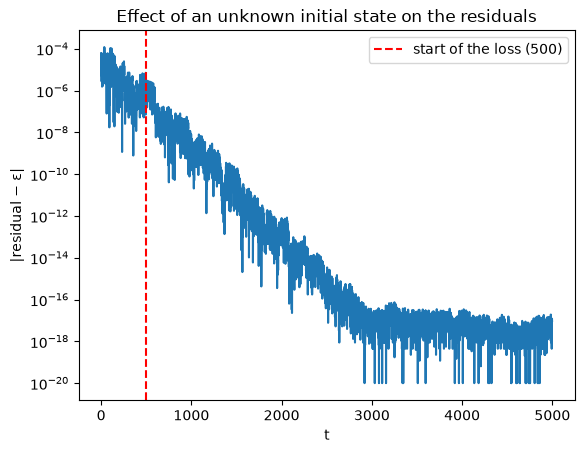

Max error before t = 500: 1.2e-04 | after: 3.0e-06
σ̂ = std of residuals (t ≥ 500): 0.003003  (true σ = 0.003)
Loss at the true θ: 9.021e-06  (≈ σ² = 9.000e-06)


In [5]:
e_no_init = residuals(THETA_TRUE, p)   # m0 = 0, v0 = p[0]
error = np.abs(e_no_init - eps_expected)

plt.semilogy(error + 1e-20)
plt.axvline(500, color="red", ls="--", label="start of the loss (500)")
plt.xlabel("t")
plt.ylabel("|residual − ε|")
plt.title("Effect of an unknown initial state on the residuals")
plt.legend()
plt.show()

print(f"Max error before t = 500: {error[:500].max():.1e} | after: {error[500:].max():.1e}")
print(f"σ̂ = std of residuals (t ≥ 500): {e_no_init[500:].std():.6f}  (true σ = {THETA_TRUE['sigma']})")
print(f"Loss at the true θ: {trajectory_loss(THETA_TRUE, p):.3e}  (≈ σ² = {THETA_TRUE['sigma']**2:.3e})")

## 4.2 Optimization

### (a) γ, α, λ fixed: a plain linear regression

With α and λ fixed, the state depends only on observed prices; with γ fixed, $F_t = (v_t-p_t)^3-(v_{t-1}-p_{t-1})^3$ and $C_t = \tanh(\gamma m_t)-\tanh(\gamma m_{t-1})$ are known numbers. The model becomes $r(t+1) = \kappa F_t + \beta C_t + \varepsilon_{t+1}$: ordinary least squares give κ and β in closed form, with standard errors $\hat\sigma^2 (X^\top X)^{-1}$.

In [6]:
import time

from joblib import Parallel, delayed

# estimate_ols (regression of r(t+1) on F_t and C_t) is defined in abm.py
fixed = {k: THETA_TRUE[k] for k in ["gamma", "alpha", "lam"]}
res = estimate_ols(p, **fixed)
for name in ["beta", "kappa"]:
    print(f"{name:6s} = {res[name]:8.4f}  ± {1.96 * res['se_' + name]:.4f}   (true: {THETA_TRUE[name]})")
print(f"sigma  = {res['sigma']:.6f}   (true: {THETA_TRUE['sigma']})")
print(f"correlation between F and C: {res['corr_F_C']:+.3f}")

beta   =   0.0442  ± 0.0368   (true: 0.05)
kappa  =  49.6058  ± 17.7846   (true: 50)
sigma  = 0.003003   (true: 0.003)
correlation between F and C: -0.639


**Monte Carlo** on the same 50 series as the GMM, for a direct comparison.

In [7]:
series = [chiarella_fast(**THETA_TRUE, T=5000, rng=np.random.default_rng(s))[0] for s in DATA_SEEDS]

t0 = time.perf_counter()
ols = pd.DataFrame([estimate_ols(s, **fixed) for s in series])
print(f"50 regressions in {time.perf_counter() - t0:.2f} s")

x_true = np.array([THETA_TRUE[k] for k in ["beta", "kappa", "sigma"]])
estimates_ols = ols[["beta", "kappa", "sigma"]].to_numpy()
rmse_ols = 100 * np.sqrt(((estimates_ols - x_true) ** 2).mean(axis=0)) / x_true

pd.DataFrame({
    "GMM (Part 2), RMSE %": [71.3, 59.7, 1.3],
    "Least squares, RMSE %": rmse_ols,
    "empirical std (MC)": estimates_ols.std(axis=0),
    "mean theoretical std error": [ols["se_beta"].mean(), ols["se_kappa"].mean(), np.nan],
}, index=["beta", "kappa", "sigma"]).round(4)

50 regressions in 0.07 s


,"GMM (Part 2), RMSE %","Least squares, RMSE %",empirical std (MC),mean theoretical std error
beta,71.3,41.3029,0.0205,0.0183
kappa,59.7,17.0681,8.5339,10.0169
sigma,1.3,1.2169,0.0000,NaN


**What to look at**: left, the (β, κ) estimates cluster around the true value instead of spreading along the GMM's c − g valley; right, the correlation between F and C (≈ −0.6): the two mechanisms partly look alike, which inflates the uncertainty.

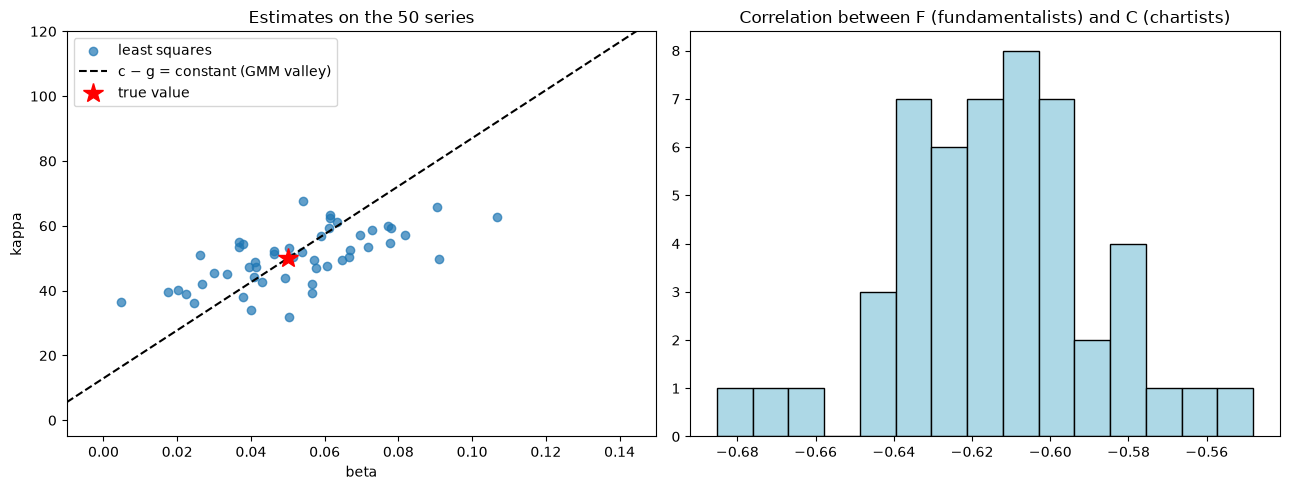

In [8]:
th = THETA_TRUE
slope = 3 * th["sigma"] ** 2 / (2 * th["lam"]) / (th["gamma"] * th["alpha"])
k = np.linspace(0, 200, 50)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(ols["beta"], ols["kappa"], alpha=0.7, label="least squares")
axes[0].plot(th["beta"] + slope * (k - th["kappa"]), k, "k--", label="c − g = constant (GMM valley)")
axes[0].plot(th["beta"], th["kappa"], "r*", markersize=15, label="true value")
axes[0].set_xlim(-0.01, 0.15)
axes[0].set_ylim(-5, 120)
axes[0].set_xlabel("beta")
axes[0].set_ylabel("kappa")
axes[0].set_title("Estimates on the 50 series")
axes[0].legend()

axes[1].hist(ols["corr_F_C"], bins=15, color="lightblue", edgecolor="k")
axes[1].set_title("Correlation between F (fundamentalists) and C (chartists)")
plt.tight_layout()
plt.savefig("../figures/trajectory_regression.png", dpi=150, bbox_inches="tight")  # README figure
plt.show()

### (b) Five free parameters (β, κ, γ, α, λ): non-linear optimization

γ sits inside the tanh, α and λ in the recursions: the problem is no longer linear. I compare **multi-start L-BFGS-B** (local) and **simulated annealing** (`dual_annealing`, global: random jumps whose size shrinks over time, so it can escape local minima). The optimization runs in $[0,1]^5$ so all parameters share the same scale.

In [9]:
from scipy.optimize import dual_annealing, minimize

PARAMS_5 = ["beta", "kappa", "gamma", "alpha", "lam"]
BOUNDS_5 = np.array([(0, 0.5), (0, 200), (0.5, 20), (0.01, 0.99), (0.001, 0.2)])
LOW_5, WIDTH_5 = BOUNDS_5[:, 0], BOUNDS_5[:, 1] - BOUNDS_5[:, 0]


def u_to_theta(u):
    """Optimize u in [0, 1]⁵ (same scale for all parameters), then θ = low + u · width."""
    return dict(zip(PARAMS_5, LOW_5 + np.asarray(u) * WIDTH_5))


def normalized_loss(u, p, var_r):
    """Trajectory loss divided by the return variance: close to 1 when the model explains little."""
    return trajectory_loss(u_to_theta(u), p) / var_r


def estimate_lbfgs(p, n_starts=10, seed=0):
    """L-BFGS-B from n_starts random points; keep the best."""
    var_r = np.var(np.diff(p))
    rng_s = np.random.default_rng(seed)
    best = None
    for _ in range(n_starts):
        res = minimize(normalized_loss, rng_s.uniform(0, 1, 5), args=(p, var_r),
                       method="L-BFGS-B", bounds=[(0, 1)] * 5)
        if best is None or res.fun < best.fun:
            best = res
    return u_to_theta(best.x), best.fun


def estimate_annealing(p, seed=0):
    """Simulated annealing (dual annealing): global search with built-in L-BFGS-B refinement."""
    var_r = np.var(np.diff(p))
    res = dual_annealing(normalized_loss, bounds=[(0, 1)] * 5, args=(p, var_r), maxiter=200, seed=seed)
    return u_to_theta(res.x), res.fun

**Test on one series**: both optimizers on the same fake market, against the loss at the true θ. Watch for equal losses with different β and γ but the same product βγ (β–γ degeneracy).

In [10]:
methods = [("L-BFGS-B (10 starts)", estimate_lbfgs), ("Simulated annealing", estimate_annealing)]
for name, method in methods:
    t0 = time.perf_counter()
    theta_hat, loss = method(p)
    duration = time.perf_counter() - t0
    print(f"{name:22s} ({duration:4.1f} s) loss = {loss:.6f} | " +
          ", ".join(f"{k}={theta_hat[k]:.4g}" for k in PARAMS_5))
print("True value".ljust(46) + " | " + ", ".join(f"{k}={THETA_TRUE[k]:.4g}" for k in PARAMS_5))
u_true = (np.array([THETA_TRUE[k] for k in PARAMS_5]) - LOW_5) / WIDTH_5
print(f"Loss at the true θ: {normalized_loss(u_true, p, np.var(np.diff(p))):.6f}")

L-BFGS-B (10 starts)   ( 2.3 s) loss = 1.004147 | beta=0.02744, kappa=74.69, gamma=7.819, alpha=0.2118, lam=0.01429
Simulated annealing    ( 1.5 s) loss = 1.004147 | beta=0.07146, kappa=74.69, gamma=3.002, alpha=0.2118, lam=0.01429
True value                                     | beta=0.05, kappa=50, gamma=10, alpha=0.1, lam=0.01
Loss at the true θ: 1.004709


**Monte Carlo**: RMSE of each parameter and of the two combinations c = βγα and g = 3κσ²/(2λ).

In [11]:
results_nl = {}
for name, method in methods:
    t0 = time.perf_counter()
    outputs = Parallel(n_jobs=-1)(delayed(method)(s) for s in series)
    results_nl[name] = pd.DataFrame([th for th, _ in outputs])
    print(f"{name:22s}: {time.perf_counter() - t0:.0f} s")


def add_c_and_g(df):
    """The combinations visible in the data: c = βγα (chartists), g = 3κσ²/(2λ) (fundamentalists)."""
    df = df.copy()
    df["c = βγα"] = df["beta"] * df["gamma"] * df["alpha"]
    df["g = 3κσ²/2λ"] = 3 * df["kappa"] * THETA_TRUE["sigma"] ** 2 / (2 * df["lam"])
    return df


truth = add_c_and_g(pd.DataFrame([THETA_TRUE])).iloc[0]
table = {}
for name, df in results_nl.items():
    df = add_c_and_g(df)
    table[name] = 100 * np.sqrt(((df - truth[df.columns]) ** 2).mean()) / truth[df.columns].abs()
pd.DataFrame(table).round(1).rename_axis("relative RMSE (%)")

L-BFGS-B (10 starts)  : 30 s
Simulated annealing   : 9 s


,L-BFGS-B (10 starts),Simulated annealing
relative RMSE (%),,
beta,476.9,296.2
kappa,52.0,51.9
gamma,68.3,68.4
alpha,256.8,255.6
lam,41.5,41.4
c = βγα,42.9,41.3
g = 3κσ²/2λ,21.3,20.9


**Histograms** (simulated annealing): the individual parameters are widely spread (β too large, γ too small, but their product is right), while c = βγα and g = 3κσ²/(2λ) are centred on the truth.

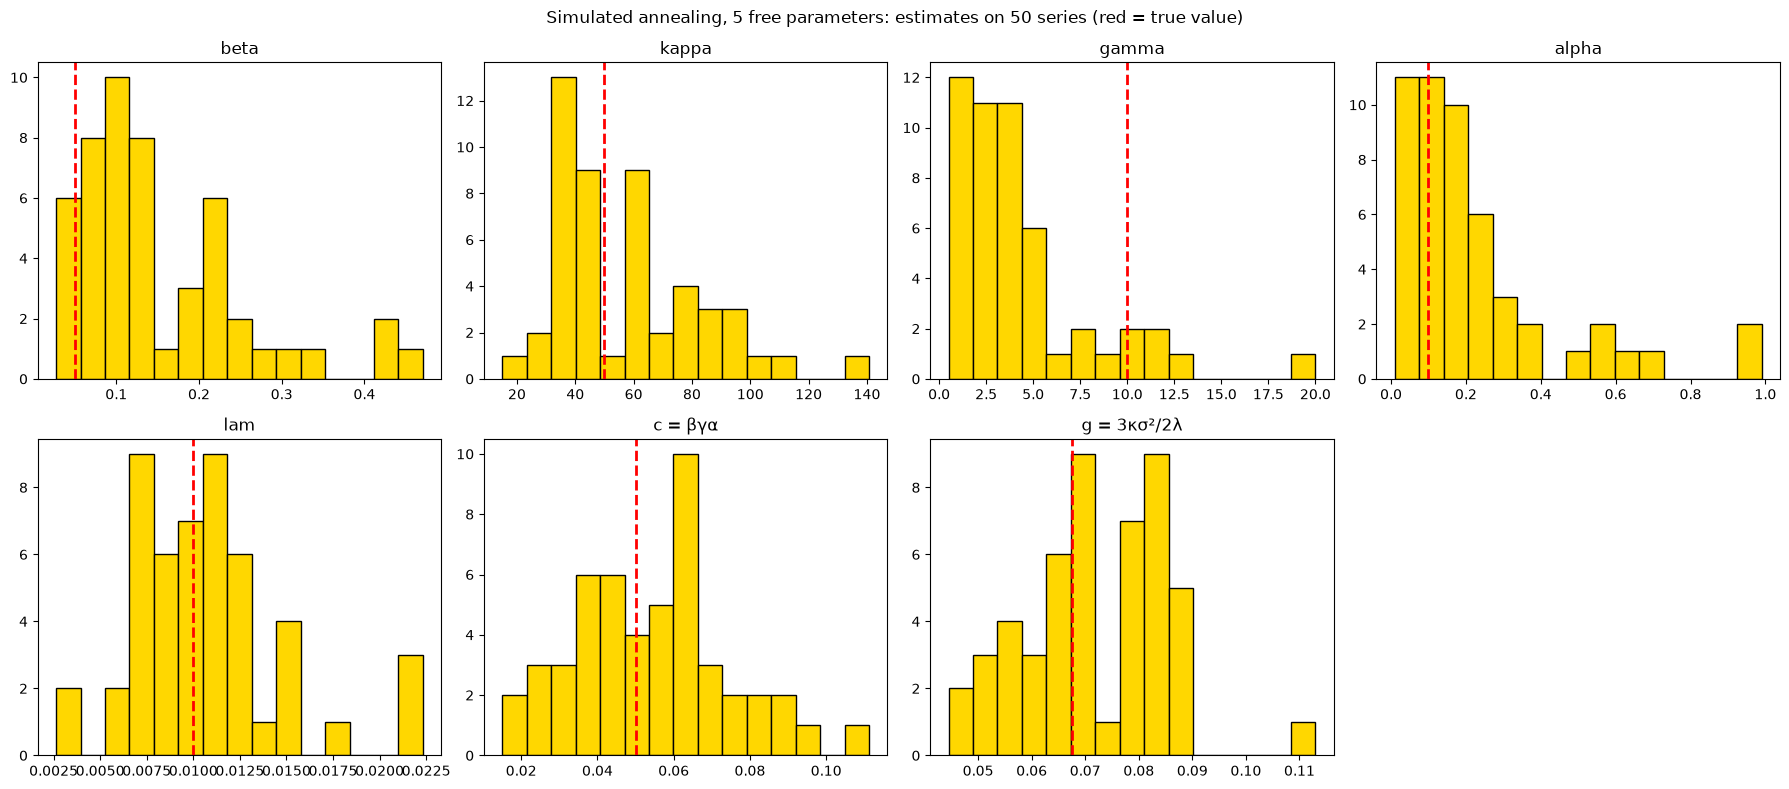

In [12]:
df_fig = add_c_and_g(results_nl["Simulated annealing"])
columns = PARAMS_5 + ["c = βγα", "g = 3κσ²/2λ"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), columns):
    ax.hist(df_fig[col], bins=15, color="gold", edgecolor="k")
    ax.axvline(truth[col], color="red", ls="--", lw=2)
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.suptitle("Simulated annealing, 5 free parameters: estimates on 50 series (red = true value)")
plt.tight_layout()
plt.show()

### What 4.2 shows

**(a) γ, α, λ fixed: the regression clearly beats the GMM** on the same 50 series (β 41 % vs 71 %, κ 17 % vs 60 %, σ 1.2 % vs 1.3 %).
- κ becomes well identified: step by step, we see **when** the gap to the fundamental is large, whereas the GMM only saw an average.
- The theoretical standard errors match the Monte Carlo spread (β: 0.018 vs 0.021; κ: 10 vs 8.5): regression theory quantifies the uncertainty without simulation.
- 50 regressions take 0.1 s, against ≈ 20 s for the GMM.

**(b) Five free parameters: precision collapses.** Both optimizers reach **the same minimal loss** with different β and γ but the **same product βγ**: the optimizers work, the problem is ill-posed. RMSE ≈ β 300 %, α 250 %, γ 70 %, κ 50 %, λ 40 %; yet **c ≈ 40 % and g ≈ 20 %** remain estimable.

The trajectory method uses the information far better than the GMM, but cannot create information the data do not contain: β, γ, α are only visible through their product.

## 4.3 Summary

β, κ, σ estimated, γ, α, λ fixed at their true value; GMM and surrogate columns come from Parts 2 and 3 (same 50 series).

In [13]:
summary = pd.DataFrame({
    "numba GMM (Part 2)": [71.3, 59.7, 1.3, 2.6],
    "surrogate GMM (Part 3)": [67.8, 54.4, 1.5, 0.044],
    "Trajectory: least squares (4.2a)": list(rmse_ols) + [np.nan],
}, index=["RMSE β (%)", "RMSE κ (%)", "RMSE σ (%)", "time per calibration (s)"])

t0 = time.perf_counter()
for s in series:
    estimate_ols(s, **fixed)
summary.loc["time per calibration (s)", "Trajectory: least squares (4.2a)"] = (time.perf_counter() - t0) / len(series)
summary.round(4)

,numba GMM (Part 2),surrogate GMM (Part 3),Trajectory: least squares (4.2a)
RMSE β (%),71.3,67.800,41.3029
RMSE κ (%),59.7,54.400,17.0681
RMSE σ (%),1.3,1.500,1.2169
time per calibration (s),2.6,0.044,0.0020


### Precision vs noise σ

In this model, changing σ also changes the fundamentalists' strength, since g = 3κσ²/(2λ): more noise means larger gaps to the fundamental, hence a more visible cubic term.

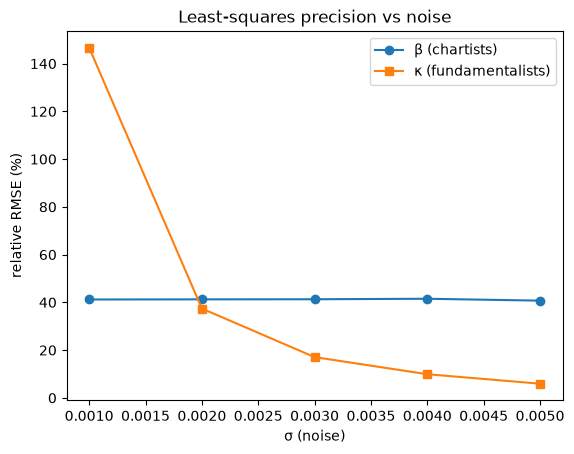

,sigma,g = 3κσ²/2λ,series used,RMSE β (%),RMSE κ (%)
0,0.001,0.007,50,41.201,146.665
1,0.002,0.030,50,41.257,37.403
2,0.003,0.068,50,41.303,17.068
3,0.004,0.120,50,41.511,9.901
4,0.005,0.188,50,40.719,5.934


In [14]:
sigmas = [0.001, 0.002, 0.003, 0.004, 0.005]
rows_snr = []
for sigma in sigmas:
    theta_s = {**THETA_TRUE, "sigma": sigma}
    estimates_s = []
    for g in DATA_SEEDS:
        p_s = chiarella_fast(**theta_s, T=5000, rng=np.random.default_rng(g))[0]
        if np.isnan(p_s).any():  # exploding series: skipped
            continue
        res_s = estimate_ols(p_s, **fixed)
        estimates_s.append([res_s["beta"], res_s["kappa"]])
    estimates_s = np.array(estimates_s)
    true_s = np.array([THETA_TRUE["beta"], THETA_TRUE["kappa"]])
    rmse_s = 100 * np.sqrt(((estimates_s - true_s) ** 2).mean(axis=0)) / true_s
    g_s = 3 * THETA_TRUE["kappa"] * sigma ** 2 / (2 * THETA_TRUE["lam"])
    rows_snr.append({"sigma": sigma, "g = 3κσ²/2λ": g_s, "series used": len(estimates_s),
                     "RMSE β (%)": rmse_s[0], "RMSE κ (%)": rmse_s[1]})
snr = pd.DataFrame(rows_snr)

plt.plot(snr["sigma"], snr["RMSE β (%)"], "o-", label="β (chartists)")
plt.plot(snr["sigma"], snr["RMSE κ (%)"], "s-", label="κ (fundamentalists)")
plt.xlabel("σ (noise)")
plt.ylabel("relative RMSE (%)")
plt.title("Least-squares precision vs noise")
plt.legend()
plt.show()
snr.round(3)

## Conclusion of Part 4

| | numba GMM | surrogate GMM | Trajectory (least squares) |
|---|---|---|---|
| RMSE β | 71 % | 68 % | **41 %** |
| RMSE κ | 60 % | 54 % | **17 %** |
| RMSE σ | 1.3 % | 1.5 % | 1.2 % |
| Time per calibration | 2.6 s | 0.044 s | **0.001 s** |

**Trajectory calibration is by far the most precise and the fastest**: it uses every time step instead of 4 statistics, and it is a maximum likelihood with no simulation.

**Precision vs noise.** κ goes from 147 % (σ = 0.001) to 6 % (σ = 0.005): more noise, larger gaps to the fundamental, more visible cubic term. β stays at ≈ 41 % whatever σ: chartists copy a fixed fraction of the return, so their signal-to-noise ratio only depends on the series length.

**Answers to the assignment's questions.**
- *Is λ the hardest to recover?* Not here: λ ≈ 40 %, better than β, γ, α, which only appear through c = βγα. λ is only seen through g ∝ κ/λ.
- *Which method for prediction?* **Trajectory calibration**: most precise, near-instant (so compatible with rolling recalibration), and it directly gives r̂_det, the prediction signal. γ can be fixed without loss (a unit convention in the linear regime); α and λ must be fixed from outside information or estimated with the non-linear version.

> **Good news for prediction**: r̂_det only depends on c and g, which are estimable. Two (β, γ) pairs with the same product give the same prediction.